# Machine learning forecasts and backtesting

After this block you can turn a time series into a table of lag features and forecast it with the tree-based models of Session 10, compare forecasting models fairly with rolling-origin backtesting, and report their accuracy with MAE and MASE and the coverage of their prediction intervals. In the worked example you test whether the Berlin weather improves the forecast and recommend one model with its 12-month forecast and prediction interval.

*Session 12, block 2. Course material, licence CC BY 4.0, with sections adapted from the third-party notebooks in [extras/](extras/README.md) (attribution at each section). Data: Inside Airbnb, Berlin, snapshot of 26 June 2026, and daily Berlin weather from Open-Meteo (both CC BY 4.0); the depth sections also use the Bike Sharing Demand data from OpenML.*

## Teaching map

The **core path** is what the lecturer teaches live in 45 minutes. Sections marked *(depth: self-study or if time allows)* go further; skip them in class and point students to them for self-study.

| Section | Minutes (core) | What it delivers |
|---|---|---|
| Setup · the series and the models of block 1 | 2 | `y`, the hold-out year, ETS and the airline model as functions |
| 1 · Machine learning with lag features | 12 | Lags, the growth target, gradient boosting on 43 rows. Depth: direct against recursive forecasts, lag and target transforms, lag features on hourly bike demand, quantile regression, calendar encodings |
| 2 · Rolling-origin backtesting | 10 | Six forecast origins, seven models, errors per fold. Depth: refit, sliding windows, gaps, strides, `TimeSeriesSplit`, refit against no refit |
| 3 · Forecast metrics: MAE and MASE | 7 | MASE with a seasonal scale, coverage, the summary table. Depth: the metric zoo, the MASE scale, pinball loss |
| Worked example · Berlin next year | 14 | Does the weather help? Recommendation with a 12-month forecast and interval |
| **Total core** | **45** | |

```mermaid
flowchart LR
    S["Series y"] --> L["Lag table<br/>(lag 12, lag 24, month)"]
    L --> M["Gradient boosting"]
    S --> E["ETS, airline,<br/>baselines"]
    M --> B["Backtest from<br/>six origins"]
    E --> B
    B --> R["MAE, MASE,<br/>coverage"]
    R --> W["Weather test and<br/>recommendation"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Setup · the series and the models of block 1

Next we import the libraries and rebuild what block 1 produced: the monthly review series `y` (January 2016 to May 2026), its log, the hold-out year, the pandemic months and the `mae` function. Nothing here is new.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 12)
DATA = Path("case-study/data/airbnb")

reviews = pd.read_parquet(DATA / "reviews_monthly.parquet")
y = reviews.groupby("month")["n_reviews"].sum()["2016":"2026-05"].rename("reviews")
y.index.freq = "MS"
log_y = np.log(y)
train, test = y[:"2025-05"], y["2025-06":]
covid = pd.Series((y.index >= "2020-03-01") & (y.index <= "2021-12-01"), index=y.index)


def mae(actual, forecast):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast))))

Next the two statistical models of block 1 as functions that return a forecast table with the columns `mean`, `lower` and `upper` (95 % interval) for the months in `index`: ETS on the log counts since 2022, and the airline model with the pandemic months marked as missing.

In [3]:
def ets_forecast(y_tr, index):
    model = ETSModel(np.log(y_tr["2022":]), error="add", trend="add", damped_trend=True,
                     seasonal="add", seasonal_periods=12).fit(disp=False)
    frame = model.get_prediction(start=index[0], end=index[-1]).summary_frame(alpha=0.05)
    return np.exp(frame.set_axis(["mean", "lower", "upper"], axis=1))


def airline_forecast(y_tr, index, exog=None, future_exog=None):
    log_gap = np.log(y_tr).where(~covid[y_tr.index])                 # pandemic months -> NaN
    model = SARIMAX(log_gap, exog=exog, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    fc = model.get_forecast(len(index), exog=future_exog)
    frame = pd.concat([fc.predicted_mean, fc.conf_int(alpha=0.05)], axis=1).set_axis(["mean", "lower", "upper"], axis=1)
    return np.exp(frame.set_axis(index))

## 1 · Machine learning with lag features

A regression model needs a table: rows, feature columns, a target column. A time series is one column of values in time order. We can still use any regressor if we **turn the series into a table**: each row is a period t, the target is yₜ, and the features are **lags** (earlier values yₜ₋ₖ) and **calendar features** such as the month. To forecast ice-cream sales for next July, last July's sales are a good feature; so is "it is July".

The one rule: **a feature may only use information that is available at the moment the forecast is made.** For a forecast twelve months ahead, last month's value (lag 1) of the target month is not known yet.

Next a tiny example. `shift(k)` moves a series k steps later, so each row sees the value of k steps earlier.

**Predict before running:** how many rows of this table have no missing value?

In [4]:
tiny = pd.Series([10, 12, 14, 16, 18], name="y")
pd.DataFrame({"y": tiny, "lag1": tiny.shift(1), "lag2": tiny.shift(2)})

,y,lag1,lag2
0,10,NaN,NaN
1,12,10.0,NaN
2,14,12.0,10.0
3,16,14.0,12.0
4,18,16.0,14.0


The first rows have no past, so their lags are missing: with lags up to k, the first k rows are lost.

For a forecast of the next 12 months there are two strategies:

- **Direct**: use only lags of 12 or more. Then every feature is known for all 12 forecast months, and one model predicts all of them.
- **Recursive**: predict one month ahead with lags 1, 2, …, then feed the prediction back in as a lag for the next month. Errors can accumulate.

We use the direct strategy with lag 12, lag 24 and the month. Two more decisions:

- **Trees cannot extrapolate.** A tree predicts averages of training targets, so a forest trained on months with at most 12,000 reviews never forecasts 15,000. The remedy is to transform the target: we predict the **yearly growth on the log scale**, log yₜ − log yₜ₋₁₂ (0.16 means about 17 % more than a year earlier). The forecast is last year's value times the predicted growth. Past growth rates *do* cover the range of future ones.
- **The break damages lags.** A row whose target, lag 12 or lag 24 falls into the pandemic describes a growth that will not repeat. We drop those rows, which leaves few rows for training.

Next we build the table. `covid.shift(12, fill_value=False)` marks rows whose lag 12 is a pandemic month.

In [5]:
table = pd.DataFrame({"target": log_y - log_y.shift(12),             # yearly growth on the log scale
                      "lag12": log_y.shift(12), "lag24": log_y.shift(24), "month": y.index.month})
touched = covid | covid.shift(12, fill_value=False) | covid.shift(24, fill_value=False)
table = table[~touched].dropna()
print(len(table), "usable rows from", table.index[0].date(), "to", table.index[-1].date())
table.tail(3).round(2)

55 usable rows from 2018-01-01 to 2026-05-01


,target,lag12,lag24,month
month,,,,
2026-03-01,0.16,9.12,8.94,3
2026-04-01,0.10,9.27,9.10,4
2026-05-01,0.23,9.39,9.24,5


Next we fit `HistGradientBoostingRegressor` (Session 10) on the rows up to May 2025 and forecast the hold-out year. `min_samples_leaf=5` is needed because the default of 20 leaves almost no splits on so few rows. The forecast is `exp(lag12 + predicted growth)`. We wrap this in a function, because the backtest will refit it from several origins.

In [6]:
def lag_forecast(y_tr, index, data=table):
    rows = data.loc[:y_tr.index[-1]]
    model = HistGradientBoostingRegressor(min_samples_leaf=5, random_state=0).fit(
        rows.drop(columns="target"), rows["target"])
    return pd.Series(np.exp(data.loc[index, "lag12"] + model.predict(data.loc[index].drop(columns="target"))),
                     index=index)


lag_fc = lag_forecast(train, test.index)
print(len(table.loc[:"2025-05"]), "training rows; hold-out MAE", round(mae(test, lag_fc)))

43 training rows; hold-out MAE 1011


The lag model is about as good as the seasonal naive × growth rule of block 1 (MAE about 1,040) and worse than ETS and the airline model. On a single short series there is little for a flexible model to learn beyond what "last year times growth" already says. Lag features shine when there is a lot of data: many series in one model (the top solutions of the M5 competition on Walmart sales used gradient boosting on lags across thousands of products; Makridakis, Spiliotis and Assimakopoulos, 2022), external features such as prices and events, or high-frequency data (section 1.2).

> **Note.** Lag 1 in a 12-month-ahead forecast is leakage: in a backtest the true value of last month is available, in reality it is not. Check every feature: would I know this value on the day I make the forecast?

> **Note.** Rolling means must be shifted too. A 3-month rolling mean that includes the target month uses the target to predict itself. Compute it on the shifted series: `y.shift(12).rolling(3).mean()`.

### 1.1 · Direct against recursive, lag transforms and target transforms *(depth: self-study or if time allows)*

*The vocabulary of this section (lags, lag transforms, date features, target transforms, recursive forecasting) follows [MLForecast end-to-end walkthrough](extras/10-mlforecast-walkthrough.ipynb) (Nixtla, Apache-2.0); the code is plain pandas and scikit-learn on the Berlin series.*

Forecasting libraries such as MLForecast build the lag table for you from four ingredients:

- **lags**: `lags=[12, 24]` adds yₜ₋₁₂ and yₜ₋₂₄;
- **lag transforms**: statistics over a window of an already shifted series, such as the rolling or expanding mean of lag 12;
- **date features**: functions of the date, such as the month or the day of the week;
- **target transforms**: a transformation of the target before fitting that is undone after predicting, for example a difference at lag 12 (our growth target) or a scaling per series.

Next we show a lag transform: the mean of lags 12 to 14, computed with `shift(12).rolling(3).mean()`. It only uses values that are at least twelve months old, so it is safe for a 12-month horizon.

In [7]:
demo = pd.DataFrame({"y": y, "lag12": y.shift(12), "mean of lags 12-14": y.shift(12).rolling(3).mean()})
demo["2025-01":"2025-03"]

,y,lag12,mean of lags 12-14
month,,,
2025-01-01,6775,5513.0,6064.333333
2025-02-01,7755,6065.0,5939.000000
2025-03-01,9135,7621.0,6399.666667


Next the **recursive** strategy, for comparison with our direct model. The target is the same growth gₜ = log yₜ − log yₜ₋₁₂, but the features are the growth of the last three months (gₜ₋₁, gₜ₋₂, gₜ₋₃) and the month. To forecast June 2025 we know gₜ₋₁ (May 2025); for July 2025 we must plug in our own forecast for June, and so on. The loop below does this for twelve months.

In [8]:
g = (log_y - log_y.shift(12)).where(~touched)
rec = pd.DataFrame({"target": g, "g1": g.shift(1), "g2": g.shift(2), "g3": g.shift(3), "month": y.index.month}).dropna()
rows = rec.loc[:"2025-05"]
rec_model = HistGradientBoostingRegressor(min_samples_leaf=5, random_state=0).fit(rows.drop(columns="target"), rows["target"])
history = list(g[:"2025-05"].to_numpy())
for date in test.index:                                  # one step at a time, feeding predictions back
    x = pd.DataFrame([[history[-1], history[-2], history[-3], date.month]], columns=["g1", "g2", "g3", "month"])
    history.append(rec_model.predict(x)[0])
rec_fc = np.exp(log_y.shift(12)[test.index] + np.array(history[-12:]))
print(len(rows), "training rows; recursive MAE", round(mae(test, rec_fc)), "| direct MAE", round(mae(test, lag_fc)))

49 training rows; recursive MAE 907 | direct MAE 1011


On this hold-out year the recursive model happens to do somewhat better. It can react to the latest growth (a strong spring carries into the summer forecast), but every step feeds a forecast back in as if it were data, so errors can compound over the horizon. Which strategy wins depends on the series; libraries offer both (MLForecast, skforecast's `ForecasterRecursive` and `ForecasterDirect`). With so few rows, neither has much to learn here.

### 1.2 · Lag features on a long series: hourly bike demand *(depth: self-study or if time allows)*

*Adapted from [Lagged features for time series forecasting](extras/08-lagged-features-gradient-boosting.ipynb) (scikit-learn developers, BSD-3-Clause); the feature engineering is rewritten in pandas (the original uses Polars).*

Lag models need data. The Bike Sharing Demand dataset (Washington D.C., 2011–2012) has 17,379 hourly counts of rented bikes. The task: predict the demand of the **next hour** from past demand. Next we load it from OpenML with `fetch_openml` (downloaded once and cached in your home directory, not in the repository).

In [9]:
from sklearn.datasets import fetch_openml

bikes = fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True).frame
count = bikes["count"].astype(float)
print(bikes.shape)
bikes[["season", "year", "month", "hour", "weekday", "weather", "temp", "count"]].head(3)

(17379, 13)


,season,year,month,hour,weekday,weather,temp,count
0,spring,0,1,0,6,clear,9.84,16
1,spring,0,1,1,6,clear,9.02,40
2,spring,0,1,2,6,clear,9.02,32


Next we build lag features for a one-hour-ahead forecast: the demand 1, 2 and 3 hours earlier, one day earlier (24 hours) and one week earlier (168 hours), each also one hour before that, plus rolling mean, maximum and minimum over the last day and the last week. Every rolling statistic is computed on `shift(1)`, so it only sees the past.

In [10]:
past = count.shift(1)
lagged = pd.DataFrame({"count": count,
                       **{f"lag_{i}h": count.shift(i) for i in (1, 2, 3)},
                       "lag_1d": count.shift(24), "lag_1d_1h": count.shift(25),
                       "lag_7d": count.shift(168), "lag_7d_1h": count.shift(169)})
for name, window in {"24h": 24, "7d": 168}.items():
    roll = past.rolling(window)
    lagged[f"mean_{name}"], lagged[f"max_{name}"], lagged[f"min_{name}"] = roll.mean(), roll.max(), roll.min()
print(lagged.isna().sum().max(), "rows with missing lags at the start")
lagged = lagged.dropna()
X, target = lagged.drop(columns="count"), lagged["count"]
X.shape

169 rows with missing lags at the start


(17210, 13)

> **Note.** `shift(24)` means "24 rows earlier". The OpenML data have a few missing hours, so 24 rows is not always exactly one day. For a careful analysis, first `reindex` to a complete hourly range (section 2 of block 1), then shift.

**A naive evaluation.** Next we split the rows at random with `train_test_split` (as for independent observations in Session 7), fit gradient boosting and compute the mean absolute percentage error (MAPE). The data are *not* independent: neighbouring hours are almost the same, and a random split puts hours from the "future" of each test hour into training.

In [11]:
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, target, test_size=0.2, random_state=42)
naive_model = HistGradientBoostingRegressor(random_state=0).fit(X_tr, y_tr)
print("random split MAPE:", round(mean_absolute_percentage_error(y_te, naive_model.predict(X_te)), 3))

random split MAPE: 0.386


**A proper evaluation.** `TimeSeriesSplit` keeps time order: each test block comes after its training block. `gap=48` leaves two days between them, `max_train_size=10000` keeps training sets of similar size, and `test_size=3000` gives about four months of test hours. Next we evaluate the same model on three such splits with `cross_val_score`.

In [12]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

ts_cv = TimeSeriesSplit(n_splits=3, gap=48, max_train_size=10000, test_size=3000)
cv_mape = -cross_val_score(HistGradientBoostingRegressor(random_state=0), X, target, cv=ts_cv,
                           scoring="neg_mean_absolute_percentage_error")
print("time-based MAPE per split:", cv_mape.round(3), "| mean", round(cv_mape.mean(), 3), "+/-", round(cv_mape.std(), 3))

time-based MAPE per split: [0.458 0.283 0.364] | mean 0.368 +/- 0.072


Here the random split does not look better than the time-based mean: for a one-hour-ahead forecast the lags already contain the neighbouring hours, so the leak through a random split adds little, and the time-based splits vary a lot (from about 0.28 to 0.46) depending on the season they cover. The scikit-learn example on which this section is based found the random split too optimistic; with longer horizons, slowly changing data or features that summarise the future, it usually is. The point that holds in every case: only the time-based split mirrors how the model will be used, and only it shows the variability from period to period. In practice, use more splits and report the mean with its spread.

**Choosing the loss.** `HistGradientBoostingRegressor` can minimise different losses: `squared_error` (estimates the conditional mean), `poisson` (a mean for counts, never negative) and `absolute_error` (the conditional median). Next we compare them with MAE and RMSE on the same splits. `cross_validate` returns several scores at once.

In [13]:
from sklearn.model_selection import cross_validate

rows = {}
for loss in ("squared_error", "poisson", "absolute_error"):
    cv = cross_validate(HistGradientBoostingRegressor(loss=loss, random_state=0), X, target, cv=ts_cv,
                        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"})
    rows[loss] = {m: f"{-cv[f'test_{m}'].mean():.1f} +/- {cv[f'test_{m}'].std():.1f}" for m in ("MAE", "RMSE")}
pd.DataFrame(rows).T

,MAE,RMSE
squared_error,39.5 +/- 2.9,63.0 +/- 3.8
poisson,39.1 +/- 2.6,63.8 +/- 3.8
absolute_error,39.4 +/- 2.6,64.0 +/- 3.5


The differences between losses are small compared with the spread across splits. The squared error is best on RMSE, the metric it optimises; on MAE the three losses are within a fraction of a bike of each other. In general, fit with the loss you will be judged by, and do not read much into differences smaller than the spread.

**Quantile regression for intervals.** Instead of the mean, a model can estimate a **quantile** of the demand: with `loss="quantile", quantile=0.05` the model aims to be above the actual value 95 % of the time. Fitting the 5 % and 95 % quantiles gives a 90 % prediction interval without assuming any distribution. Demand is uncertain even with perfect features (whether it rains next hour is not in the lags); this is called *aleatoric* uncertainty. Next we fit the 5 %, 50 % and 95 % quantiles on the first split and plot the last four days of its test block.

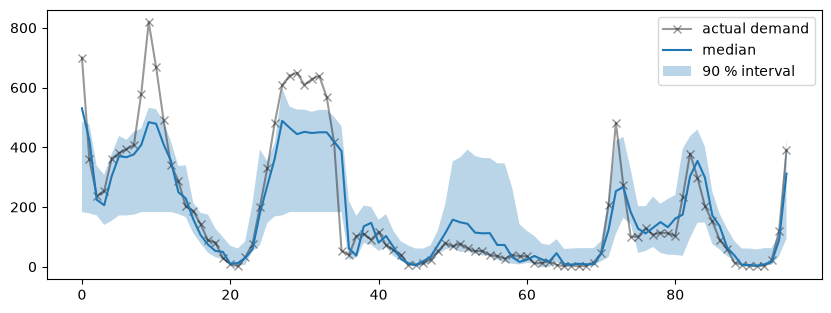

In [14]:
train_idx, test_idx = next(ts_cv.split(X))
quantiles = {}
for q in (0.05, 0.5, 0.95):
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=50, random_state=0)
    quantiles[q] = m.fit(X.iloc[train_idx], target.iloc[train_idx]).predict(X.iloc[test_idx])
actual = target.iloc[test_idx].to_numpy()
last = slice(-96, None)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(actual[last], "x-", color="black", alpha=0.4, label="actual demand")
ax.plot(quantiles[0.5][last], label="median")
ax.fill_between(np.arange(96), quantiles[0.05][last], quantiles[0.95][last], alpha=0.3, label="90 % interval")
ax.legend();

The band is narrow at night, when the models are sure that few bikes are rented, and wide during the day, when weather and leisure use make demand uncertain. The commuting peaks of working days remain visible. A 90 % interval should contain about 90 % of the actual values; next we check this **empirical coverage** on the whole test block.

In [15]:
coverage = np.mean((actual >= quantiles[0.05]) & (actual <= quantiles[0.95]))
print(f"empirical coverage of the 90 % interval: {coverage:.2f}")

empirical coverage of the 90 % interval: 0.80


Coverage below the nominal 90 % means the quantile models are somewhat overconfident on new data; conformal methods (for example the MAPIE library) calibrate such intervals with held-out errors.

### 1.3 · Encoding calendar features *(depth: self-study or if time allows)*

*Adapted from [Time-related feature engineering](extras/09-time-related-feature-engineering.ipynb) (scikit-learn developers, BSD-3-Clause).*

Calendar features (hour, weekday, month) are periodic: hour 23 is next to hour 0, December next to January. Trees can learn any pattern from the raw integers, but **linear models** cannot: a single coefficient on `hour` says demand rises (or falls) steadily from midnight to 23:00. Four encodings, compared on the bike data with a ridge regression:

1. **ordinal**: the raw integers, scaled to 0–1;
2. **one-hot**: one column per hour, weekday and month, so any pattern is possible, at the cost of many columns and no notion of neighbouring hours;
3. **sine and cosine**: each periodic feature becomes two smooth columns, sin(2π·x/period) and cos(2π·x/period), with no jump between the last and first value;
4. **periodic splines**: several smooth bumps along the cycle (`SplineTransformer(extrapolation="periodic")`), more flexible than one sine and cosine pair.

Here the target is the demand as a fraction of the maximum, so an MAE of 0.10 means 10 % of the peak demand. Next we prepare the features: the weather and calendar columns of the dataset (no lags), with the rare "heavy rain" category merged into "rain".

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder, SplineTransformer

Xc = bikes.drop(columns="count")
Xc["weather"] = Xc["weather"].astype(object).replace("heavy_rain", "rain").astype("category")
yc = bikes["count"] / bikes["count"].max()
categorical = Xc.columns[Xc.dtypes == "category"]
cv5 = TimeSeriesSplit(n_splits=5, gap=48, max_train_size=10000, test_size=1000)
print("categorical:", categorical.to_list())

categorical: ['season', 'holiday', 'workingday', 'weather']


Next the encoders. `FunctionTransformer` wraps the sine and cosine formulas; `SplineTransformer(n_knots=..., extrapolation="periodic")` builds periodic splines. Each pipeline one-hot encodes the categorical weather columns, encodes the calendar columns its own way, scales the rest and fits `RidgeCV`.

In [17]:
def sin_cos(period):
    return [FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi), feature_names_out="one-to-one"),
            FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi), feature_names_out="one-to-one")]


def periodic_spline(period, n_splines):
    return SplineTransformer(degree=3, n_knots=n_splines + 1, knots=np.linspace(0, period, n_splines + 1).reshape(-1, 1),
                             extrapolation="periodic", include_bias=True)


onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
cyclic = {"hour": 24, "weekday": 7, "month": 12}
encodings = {
    "ordinal": [],
    "one-hot": [("time", onehot, list(cyclic))],
    "sine/cosine": [(f"{c}_{f}", t, [c]) for c, p in cyclic.items() for f, t in zip(("sin", "cos"), sin_cos(p))],
    "periodic splines": [(f"{c}_spline", periodic_spline(p, {24: 12, 7: 3, 12: 6}[p]), [c]) for c, p in cyclic.items()],
}

Next we evaluate each encoding with five time-based splits and add gradient boosting on the raw columns as a reference. `categorical_features="from_dtype"` lets the trees split on categories directly.

In [18]:
def cv_mae(model):
    scores = -cross_validate(model, Xc, yc, cv=cv5, scoring="neg_mean_absolute_error")["test_score"]
    return f"{scores.mean():.3f} +/- {scores.std():.3f}"


results = {}
for name, steps in encodings.items():
    pipe = make_pipeline(ColumnTransformer([("cat", onehot, categorical), *steps], remainder=MinMaxScaler()),
                         RidgeCV(alphas=np.logspace(-6, 6, 25)))
    results[f"ridge, {name}"] = cv_mae(pipe)
results["gradient boosting, raw columns"] = cv_mae(HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=42))
pd.Series(results, name="MAE (share of max demand)")

ridge, ordinal                    0.142 +/- 0.014
ridge, one-hot                    0.099 +/- 0.011
ridge, sine/cosine                0.125 +/- 0.014
ridge, periodic splines           0.097 +/- 0.011
gradient boosting, raw columns    0.044 +/- 0.003
Name: MAE (share of max demand), dtype: str

The raw ordinal encoding is far behind: a linear model cannot express "busy at 8:00 and 18:00, quiet at noon and night" with one slope per feature. One-hot and splines help a lot; sine/cosine with a single pair per feature is too smooth to capture two daily peaks. Gradient boosting on the raw columns is best without any encoding work, because trees cut the hour into intervals by themselves. The source notebook goes further: interactions between hour and working day (polynomial features or kernel approximation) close most of the remaining gap for linear models.

Next we look at what the sine/cosine and spline encodings do to the hour, for hours 0 to 25 (beyond 23 to show that they wrap around).

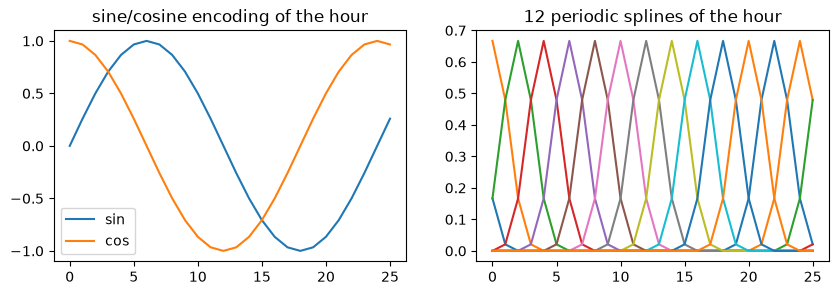

In [19]:
hours = pd.DataFrame({"hour": np.arange(26)})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
for f, t in zip(("sin", "cos"), sin_cos(24)):
    a1.plot(hours["hour"], t.fit_transform(hours)["hour"], label=f)
a1.set_title("sine/cosine encoding of the hour")
a1.legend()
a2.plot(hours["hour"], periodic_spline(24, 12).fit_transform(hours))
a2.set_title("12 periodic splines of the hour");

For our monthly Airbnb series the month enters the tree model as a plain integer, which is fine for trees. A linear model on the same table would need one of these encodings.

> 📖 **Read more:** [extras/08-lagged-features-gradient-boosting.ipynb](extras/08-lagged-features-gradient-boosting.ipynb) (scikit-learn gallery): the full lag example with Polars, pinball losses and residual plots. [extras/09-time-related-feature-engineering.ipynb](extras/09-time-related-feature-engineering.ipynb) (scikit-learn gallery): the encodings in depth, with polynomial interactions and Nyström kernel approximation. [extras/10-mlforecast-walkthrough.ipynb](extras/10-mlforecast-walkthrough.ipynb) (Nixtla MLForecast): lags, lag transforms, target transforms and LightGBM for many series at once; needs its own environment (see the session README, Setup).

## 2 · Rolling-origin backtesting

One hold-out year is one sample of forecast performance. A model can win a single year by luck. **Rolling-origin backtesting** (also called time series cross-validation) repeats the test: fit on all data up to a **forecast origin**, forecast the next h periods, move the origin forward, repeat. Each fold uses only the past to predict the future. You would not judge a weather forecaster on one day; you count how often they were right over many days.

With an **expanding window** the training data grow from fold to fold; with a **sliding window** they keep a fixed length. Here the post-pandemic history is short, so the origins move by three months, from March 2024 to June 2025: six folds of twelve test months each. The first origin leaves ETS two full years since January 2022; the last fold is the hold-out year of block 1.

```mermaid
flowchart LR
    subgraph F1["Fold 1"]
        A1["Train to Feb 2024"] --> B1["Test Mar 2024 to Feb 2025"]
    end
    subgraph F2["Fold 2"]
        A2["Train to May 2024"] --> B2["Test Jun 2024 to May 2025"]
    end
    subgraph F3["Folds 3 to 5"]
        A3["Origin moves<br/>3 months each time"] --> B3["Test 12 months"]
    end
    subgraph F6["Fold 6"]
        A6["Train to May 2025"] --> B6["Test Jun 2025 to May 2026"]
    end
    F1 --> F2 --> F3 --> F6
```

Next a function that returns the forecasts of seven models for one fold: four baselines of block 1, ETS, the airline model and the lag model. ETS and the airline model also return their 95 % intervals.

In [20]:
def all_forecasts(y_tr, index):
    last_year = y_tr.iloc[-12:].to_numpy()
    ets, air = ets_forecast(y_tr, index), airline_forecast(y_tr, index)
    point = pd.DataFrame({
        "naive": y_tr.iloc[-1], "seasonal naive": last_year, "moving average (3)": y_tr.iloc[-3:].mean(),
        "seasonal naive x growth": last_year * last_year.sum() / y_tr.iloc[-24:-12].sum(),
        "ETS": ets["mean"], "airline": air["mean"], "lag model": lag_forecast(y_tr, index),
    }, index=index)
    return point, {"ETS": ets, "airline": air}

Next the loop over the six origins. `pd.date_range(..., freq="3MS")` gives the origins; `origin - pd.offsets.MonthBegin()` is the month before, the end of the training data. We store each fold's training data, actual values, forecasts and intervals, so that section 3 can compute any metric from them.

In [21]:
folds = []
for origin in pd.date_range("2024-03-01", "2025-06-01", freq="3MS"):
    index = pd.date_range(origin, periods=12, freq="MS")
    y_tr = y[:origin - pd.offsets.MonthBegin()]
    point, intervals = all_forecasts(y_tr, index)
    folds.append({"origin": origin.strftime("%Y-%m"), "y_tr": y_tr, "y_te": y[index],
                  "point": point, "intervals": intervals})
pd.DataFrame({f["origin"]: {m: mae(f["y_te"], f["point"][m]) for m in f["point"]} for f in folds}).T.round(0)

,naive,seasonal naive,moving average (3),seasonal naive x growth,ETS,airline,lag model
2024-03,3412.0,2113.0,3538.0,722.0,1285.0,498.0,612.0
2024-06,1559.0,2038.0,1810.0,570.0,534.0,396.0,541.0
2024-09,1913.0,1705.0,1990.0,575.0,344.0,464.0,974.0
2024-12,2942.0,1630.0,2056.0,883.0,953.0,360.0,1130.0
2025-03,3227.0,1505.0,3506.0,1234.0,644.0,730.0,1334.0
2025-06,1710.0,1586.0,1935.0,1038.0,851.0,450.0,1011.0


The table shows the MAE of each model (columns) for each test period (rows, by first test month). The errors vary a lot from fold to fold, and the ranking of the models is not the same in every fold. That is exactly why one hold-out year is not enough.

> **Note.** Never use shuffled k-fold cross-validation on a time series: it puts later months into the training folds, and the error looks better than it will be in use (section 1.2 discusses when the difference is large).

### 2.1 · Backtesting strategies *(depth: self-study or if time allows)*

*Adapted from [Backtesting](extras/11-backtesting.ipynb) (skforecast developers, BSD-3-Clause) and [Time series cross-validation with StatsForecast](extras/12-statsforecast-cross-validation.ipynb) (Nixtla, Apache-2.0).*

Backtesting evaluates a model by applying it retrospectively to historical data. The setup should mirror how the model will be used: the same horizon, the same refit frequency, the same data available at each origin. The main options:

- **No refit**: train once, then forecast fold after fold without updating the parameters. Fast, but the model may lose accuracy as it ages.
- **Refit with an expanding window**: retrain before every fold on all data up to the origin (what we did above).
- **Refit with a fixed (sliding) window**: retrain on the last n periods only; older data drop out. Useful when the world changes.
- **Intermittent refit**: retrain every k folds, a compromise between cost and freshness.
- **Gap**: leave g periods between the end of training and the start of the test, for example when data arrive with a delay.
- **Fold stride**: how far the origin moves between folds. A stride equal to the horizon gives back-to-back, non-overlapping test periods; a smaller stride (ours: 3 months for a 12-month horizon) gives overlapping test periods and more folds; a larger stride leaves gaps.
- **Skip folds**: evaluate only every k-th fold to save time.

Nixtla's `cross_validation` uses the same ideas with other names: `h` (the horizon), `step_size` (the stride), `n_windows` (the number of folds) and a `cutoff` column (the last training date of each fold, our origin minus one month).

Next a small function that lists the folds of a configuration as a table, for our 125 monthly values.

In [22]:
def fold_table(dates, first_origin, horizon, stride, gap=0, window=None):
    rows, start = [], dates.get_loc(first_origin)
    for o in range(start, len(dates) - gap - horizon + 1, stride):
        train_start = 0 if window is None else max(0, o - window)
        rows.append({"train": f"{dates[train_start]:%Y-%m} to {dates[o - 1]:%Y-%m}", "n train": o - train_start,
                     "test": f"{dates[o + gap]:%Y-%m} to {dates[o + gap + horizon - 1]:%Y-%m}"})
    return pd.DataFrame(rows)


print(fold_table(y.index, "2024-03-01", horizon=12, stride=3).to_string(), "\n")
print(fold_table(y.index, "2023-06-01", horizon=12, stride=12, gap=1, window=36).to_string())

                train  n train                test
0  2016-01 to 2024-02       98  2024-03 to 2025-02
1  2016-01 to 2024-05      101  2024-06 to 2025-05
2  2016-01 to 2024-08      104  2024-09 to 2025-08
3  2016-01 to 2024-11      107  2024-12 to 2025-11
4  2016-01 to 2025-02      110  2025-03 to 2026-02
5  2016-01 to 2025-05      113  2025-06 to 2026-05 

                train  n train                test
0  2020-06 to 2023-05       36  2023-07 to 2024-06
1  2021-06 to 2024-05       36  2024-07 to 2025-06


The first table is our backtest. The second shows a sliding window of 36 months, a one-month gap (as if the data of the last month were not yet available at the origin) and non-overlapping test years.

scikit-learn's `TimeSeriesSplit` produces the same kind of folds as positions: `n_splits` folds of `test_size` rows, counted back from the end, with optional `gap` and `max_train_size` (a sliding window). Next we print its folds for our series.

In [23]:
from sklearn.model_selection import TimeSeriesSplit

for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=3, test_size=12, gap=0, max_train_size=60).split(y)):
    print(f"fold {k}: train {y.index[tr[0]]:%Y-%m} to {y.index[tr[-1]]:%Y-%m} ({len(tr)}), "
          f"test {y.index[te[0]]:%Y-%m} to {y.index[te[-1]]:%Y-%m}")

fold 0: train 2018-06 to 2023-05 (60), test 2023-06 to 2024-05
fold 1: train 2019-06 to 2024-05 (60), test 2024-06 to 2025-05
fold 2: train 2020-06 to 2025-05 (60), test 2025-06 to 2026-05


**Refit against no refit.** statsmodels can update a fitted state-space model with new observations without re-estimating its parameters: `results.append(new_data, refit=False)` keeps the coefficients and only runs the filter over the new months. Next we backtest the airline model both ways from the same six origins: refitted at every origin, and fitted once at the first origin and only updated afterwards.

In [24]:
first_end = folds[0]["y_tr"].index[-1]
base_fit = SARIMAX(np.log(y[:first_end]).where(~covid[:first_end]), order=(0, 1, 1),
                   seasonal_order=(0, 1, 1, 12)).fit(disp=False)
compare = {}
for f in folds:
    new = np.log(f["y_tr"])[first_end:].iloc[1:]                  # months added since the first origin
    updated = base_fit.append(new, refit=False) if len(new) else base_fit
    no_refit = np.exp(updated.forecast(12)).to_numpy()
    compare[f["origin"]] = {"refit": mae(f["y_te"], f["point"]["airline"]), "no refit": mae(f["y_te"], no_refit)}
pd.DataFrame(compare).T.round(0)

,refit,no refit
2024-03,498.0,498.0
2024-06,396.0,392.0
2024-09,464.0,460.0
2024-12,360.0,359.0
2025-03,730.0,722.0
2025-06,450.0,463.0


Here the two are close: the airline model's two coefficients barely change when a few months are added, so refitting buys little. For models with many parameters, or after a change in the data, refitting matters more. In production, a common pattern is to update the state every month and re-estimate the parameters less often.

> 📖 **Read more:** [extras/11-backtesting.ipynb](extras/11-backtesting.ipynb) (skforecast): animated diagrams of every backtesting strategy, `TimeSeriesFold`, intervals and exogenous variables in backtests. [extras/12-statsforecast-cross-validation.ipynb](extras/12-statsforecast-cross-validation.ipynb) (Nixtla StatsForecast): `cross_validation` with `h`, `step_size` and `n_windows` on M4 hourly data. Both need their own environment (see the session README, Setup).

## 3 · Forecast metrics: MAE and MASE

- **MAE** = mean |yₜ − ŷₜ|, in the units of the series. Easy to explain ("about 500 reviews per month off"), but not comparable across series of different size: an error of 100 is large for a district with 300 reviews a month and tiny for the city with 12,000.
- **MASE** (mean absolute scaled error; Hyndman and Koehler, 2006) divides the MAE by the in-sample MAE of the seasonal naive forecast on the **training** data: scale = mean |yₜ − yₜ₋ₘ| over the training period. MASE < 1 means the forecast errs less than the seasonal naive forecast did, on average, in the past. MASE is comparable across series and folds, and well defined when values are close to zero.
- **Coverage** of a prediction interval is the share of actual values inside it; a 95 % interval should have coverage close to 0.95 over many forecasts.

Worked example: the training series 10, 12, 14, 11, 13, 15 with m = 3. The seasonal differences are |11 − 10|, |13 − 12|, |15 − 14| = 1, 1, 1, so the scale is 1. A forecast with MAE 1.5 on the test period has MASE 1.5: it errs 50 % more than seasonal naive did in-sample.

With a break in the training data the scale needs care: the seasonal differences from 2020 to 2022 measure the collapse and recovery, not normal year-to-year variation, and the early years are at a much lower level. Our scale uses the training months since January 2022 only, the regime the forecasts are about.

Next the `mase` function, and a summary over the six folds: mean MAE, mean and worst MASE, interval coverage, and how often each model was the best.

In [25]:
def mase(actual, forecast, y_tr, m=12, since="2022"):
    history = y_tr[since:].to_numpy()                          # skip the pandemic years
    scale = np.mean(np.abs(history[m:] - history[:-m]))        # in-sample seasonal naive MAE
    return mae(actual, forecast) / scale


rows = []
for f in folds:
    for name in f["point"]:
        row = {"origin": f["origin"], "model": name, "MAE": mae(f["y_te"], f["point"][name]),
               "MASE": mase(f["y_te"], f["point"][name], f["y_tr"])}
        if name in f["intervals"]:
            iv = f["intervals"][name]
            row["coverage"] = np.mean((f["y_te"] >= iv["lower"]) & (f["y_te"] <= iv["upper"]))
        rows.append(row)
backtest = pd.DataFrame(rows)

**Predict before running:** which model has the lowest mean MASE? Does the lag model beat seasonal naive × growth?

In [26]:
summary = backtest.groupby("model").agg(MAE=("MAE", "mean"), MASE=("MASE", "mean"),
                                        MASE_worst=("MASE", "max"), coverage=("coverage", "mean"))
best = backtest.loc[backtest.groupby("origin")["MASE"].idxmin(), "model"].value_counts()
summary["folds best"] = best.reindex(summary.index).fillna(0).astype(int)
summary.sort_values("MASE").round(2)

,MAE,MASE,MASE_worst,coverage,folds best
model,,,,,
airline,482.77,0.31,0.44,1.00,4
ETS,768.50,0.51,1.01,0.83,2
seasonal naive x growth,836.94,0.54,0.74,NaN,0
lag model,933.56,0.59,0.80,NaN,0
seasonal naive,1762.78,1.17,1.65,NaN,0
naive,2460.62,1.62,2.67,NaN,0
moving average (3),2472.75,1.63,2.77,NaN,0


How to read it:

- **The airline model with the pandemic marked as missing is best on average and never bad.** It wins most folds, and its worst fold is better than the average of every other model.
- **ETS fitted since 2022 is second, but unstable.** In the first fold, with only 26 months of training data, it is clearly worse than seasonal naive × growth. A short history makes the trend estimate fragile.
- **Simple rules are hard to beat.** Seasonal naive × growth is close to ETS and ahead of the lag model; plain seasonal naive and the flat baselines are worse than the in-sample seasonal naive scale (MASE above 1), because they ignore growth or season.
- **The intervals differ in quality.** ETS covered noticeably fewer test months than its nominal 95 %: too narrow. The airline intervals covered all of them, at the cost of being wide.

### 3.1 · More metrics and the MASE scale *(depth: self-study or if time allows)*

*Adapted from [Time series forecasting metrics](extras/13-forecasting-metrics.ipynb) (skforecast developers, BSD-3-Clause) (metric table) and [Lagged features for time series forecasting](extras/08-lagged-features-gradient-boosting.ipynb) (scikit-learn developers, BSD-3-Clause) (pinball loss).*

| Metric | What it measures | Notes |
|---|---|---|
| Mean squared error (MSE), root MSE (RMSE) | squared error | Penalises large errors heavily; RMSE is in the units of the target. |
| Mean absolute error (MAE) | absolute error | Same units as the target; less sensitive to outliers than MSE. |
| Median absolute error | robust error | Ignores occasional very large errors. |
| Mean absolute percentage error (MAPE) | relative error | Scale-free, but undefined or unstable when actual values are near zero; penalises over-forecasts more than under-forecasts. |
| Symmetric MAPE (sMAPE) | relative error | Divides by the mean of actual and forecast; more stable near zero. |
| Mean absolute scaled error (MASE) | skill against a naive forecast | MAE divided by the in-sample MAE of a (seasonal) naive forecast; below 1 beats it. |
| Root mean squared scaled error (RMSSE) | skill, squared | RMSE divided by the in-sample RMSE of the naive forecast; used in the M5 competition. |
| Pinball (quantile) loss | quality of a quantile forecast | The loss that a quantile forecast minimises; used to score interval limits. |

Next we pool the forecasts of all six folds and compute these metrics for three models. The scaled ones use the scale of each fold's training data.

In [27]:
from sklearn.metrics import mean_absolute_percentage_error, median_absolute_error, root_mean_squared_error


def smape(a, f):
    return float(np.mean(2 * np.abs(f - a) / (np.abs(a) + np.abs(f))))


def rmsse(a, f, y_tr, m=12):
    h = y_tr["2022":].to_numpy()
    return root_mean_squared_error(a, f) / np.sqrt(np.mean((h[m:] - h[:-m]) ** 2))


table_rows = {}
for name in ("airline", "ETS", "seasonal naive x growth"):
    a = np.concatenate([f["y_te"].to_numpy() for f in folds])
    fc = np.concatenate([f["point"][name].to_numpy() for f in folds])
    table_rows[name] = {"MAE": mae(a, fc), "RMSE": root_mean_squared_error(a, fc), "MedAE": median_absolute_error(a, fc),
                        "MAPE": mean_absolute_percentage_error(a, fc), "sMAPE": smape(a, fc),
                        "MASE": np.mean([mase(f["y_te"], f["point"][name], f["y_tr"]) for f in folds]),
                        "RMSSE": np.mean([rmsse(f["y_te"], f["point"][name], f["y_tr"]) for f in folds])}
pd.DataFrame(table_rows).T.round(3)

,MAE,RMSE,MedAE,MAPE,sMAPE,MASE,RMSSE
airline,482.765,601.606,398.426,0.046,0.046,0.314,0.358
ETS,768.499,970.186,611.830,0.074,0.078,0.512,0.564
seasonal naive x growth,836.936,1042.973,762.721,0.076,0.074,0.537,0.606


All metrics agree on the ranking here; that is not always so (a model with rare large misses can win on MAE and lose on RMSE). Choose the metric before looking at the results, from what the errors cost the user.

**The MASE scale matters.** Next we compute the scale (the denominator of MASE) of the hold-out fold three ways: our choice (seasonal differences, m = 12, since 2022), with m = 1 (month-to-month changes), and with m = 12 over all years including the pandemic.

In [28]:
y_tr = folds[-1]["y_tr"]
scales = {"m=12, since 2022 (ours)": y_tr["2022":], "m=1, since 2022": y_tr["2022":], "m=12, since 2016": y_tr}
for (name, h), m in zip(scales.items(), (12, 1, 12)):
    h = h.to_numpy()
    print(f"{name:26s} scale {np.mean(np.abs(h[m:] - h[:-m])):7.0f}")

m=12, since 2022 (ours)    scale    1658
m=1, since 2022            scale     919
m=12, since 2016           scale    1729


The same forecast error would give different MASE values. The m = 1 scale is much smaller (month-to-month changes are smaller than year-on-year changes on a growing series), so every MASE would look worse. The all-years scale happens to be close to ours, because the small differences of the low early years offset the huge ones of the pandemic: luck, not a property to rely on. Hyndman and Koehler use m = 1 for non-seasonal data and the seasonal m for seasonal data; with a break in the training data, also decide which years enter the scale, and say so in the report.

**Scoring intervals with the pinball loss.** For a quantile level τ, the pinball loss of a forecast q is τ·(y − q) when y is above q, and (1 − τ)·(q − y) when y is below. A good lower limit (τ = 0.025) is rarely above the actual value, because that is penalised with weight 0.975. Next we score the interval limits of ETS and the airline model over all folds with `mean_pinball_loss`.

In [29]:
from sklearn.metrics import mean_pinball_loss

scores = {}
for name in ("ETS", "airline"):
    a = np.concatenate([f["y_te"].to_numpy() for f in folds])
    lo = np.concatenate([f["intervals"][name]["lower"].to_numpy() for f in folds])
    hi = np.concatenate([f["intervals"][name]["upper"].to_numpy() for f in folds])
    scores[name] = {"pinball 2.5 %": mean_pinball_loss(a, lo, alpha=0.025),
                    "pinball 97.5 %": mean_pinball_loss(a, hi, alpha=0.975),
                    "coverage": np.mean((a >= lo) & (a <= hi)), "mean width": np.mean(hi - lo)}
pd.DataFrame(scores).T.round(2)

,pinball 2.5 %,pinball 97.5 %,coverage,mean width
ETS,48.75,102.97,0.83,2826.02
airline,62.35,90.64,1.00,6119.59


Coverage alone rewards wide intervals; the pinball loss also rewards sharpness, so it balances the two. A useful interval is calibrated *and* as narrow as possible.

> 📖 **Read more:** [extras/13-forecasting-metrics.ipynb](extras/13-forecasting-metrics.ipynb) (skforecast): the full metric tables (regression, classification, probabilistic), custom metrics and how to aggregate metrics over many series. Needs its own environment (see the session README, Setup).

## Worked example · How many Airbnb stays should Berlin expect next year?

The practice question of this block: backtest the models, test whether the Berlin weather adds anything, and recommend one with its 12-month forecast and prediction interval.

### Does the Berlin weather add anything?

`case-study/prepare_airbnb.py` downloads the daily Berlin weather from the Open-Meteo API and stores it as `weather_daily.parquet`. The *season* of the weather is already in every model: July is warm and busy every year, and the month feature, the seasonal naive rule and the seasonal parts of ETS and the airline model capture that. The question is whether the *deviations* help: does a warmer or drier month than usual bring more stays than the season alone suggests?

Two things must be separated. To **explain** the past, the observed weather of each month can be used. To **forecast** twelve months ahead, it cannot: weather forecasts reach about two weeks, so at the forecast origin the only honest value for next March is the usual March weather, the **climate** (the monthly mean of the training years). We run both versions. With the observed weather it is an upper bound that no real forecast can reach; with the climate it is what a forecaster could actually do.

Next we resample the daily weather to months (mean temperature, total rain, as in block 1) and plot the yearly growth of the reviews against the change of the weather from the same month a year earlier, for the months outside the pandemic.

67 months outside the pandemic


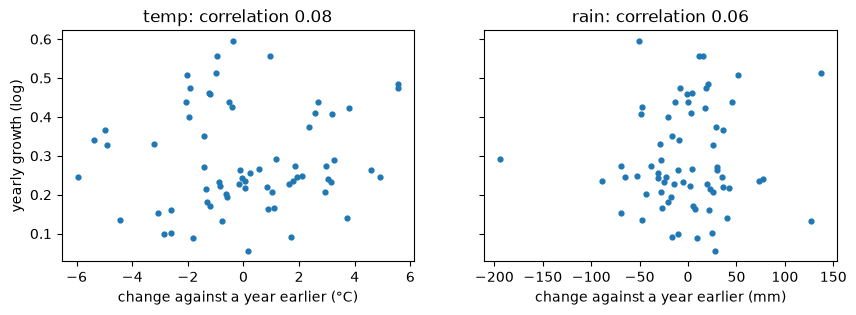

In [30]:
daily = pd.read_parquet(DATA / "weather_daily.parquet").set_index("date")
wx = daily.resample("MS").agg({"temperature_2m_mean": "mean", "precipitation_sum": "sum"}).loc[y.index]
wx.columns = ["temp", "rain"]                                       # °C (monthly mean), mm (monthly total)
pairs = pd.concat([(log_y - log_y.shift(12)).rename("growth"), wx - wx.shift(12)], axis=1)[~touched].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, col, unit in zip(axes, ["temp", "rain"], ["°C", "mm"]):
    ax.scatter(pairs[col], pairs["growth"], s=12)
    ax.set_xlabel(f"change against a year earlier ({unit})")
    ax.set_title(f"{col}: correlation {pairs.corr().loc['growth', col]:.2f}")
axes[0].set_ylabel("yearly growth (log)")
print(len(pairs), "months outside the pandemic")

Next two weather versions of the models. The lag model gets the change of temperature and rain against the same month a year earlier (its target is the growth against that month); after the origin these are either the observed values or the climate. The airline model gets the deviation from the usual month as exogenous variables (`exog`); with the climate, the future deviation is zero.

In [31]:
def weather_change(y_tr, known):
    w = wx.copy()
    later = w.index > y_tr.index[-1]
    if known == "climate":                                           # usual weather of each month
        past = wx[:y_tr.index[-1]]
        w.loc[later] = past.groupby(past.index.month).mean().loc[w.index[later].month].to_numpy()
    return (w - wx.shift(12)).add_prefix("change_")


def airline_weather(y_tr, index, known):
    past = wx[:y_tr.index[-1]]
    anomaly = wx - past.groupby(past.index.month).mean().loc[wx.index.month].to_numpy()
    future = anomaly.loc[index] if known == "actual" else 0 * anomaly.loc[index]
    return airline_forecast(y_tr, index, exog=anomaly.loc[y_tr.index], future_exog=future)["mean"]

Next the same six folds with the weather versions. `table.join(...)` adds the weather columns to the lag table, and `lag_forecast(..., data=...)` fits on it.

In [32]:
rows = []
for f in folds:
    index = f["y_te"].index
    for known in ("actual", "climate"):
        lagw = lag_forecast(f["y_tr"], index, data=table.join(weather_change(f["y_tr"], known)))
        rows.append({"model": f"lag model + weather ({known})", "MASE": mase(f["y_te"], lagw, f["y_tr"])})
        rows.append({"model": f"airline + weather ({known})",
                     "MASE": mase(f["y_te"], airline_weather(f["y_tr"], index, known), f["y_tr"])})
with_weather = pd.concat([backtest.loc[backtest["model"].isin(["airline", "lag model"]), ["model", "MASE"]],
                          pd.DataFrame(rows)])
with_weather.groupby("model")["MASE"].agg(["mean", "max"]).round(2)

,mean,max
model,,
airline,0.31,0.44
airline + weather (actual),0.32,0.57
airline + weather (climate),0.33,0.58
lag model,0.59,0.80
lag model + weather (actual),0.63,0.85
lag model + weather (climate),0.64,0.89


Finally, the size of the effect: next we fit the airline model with weather anomalies on all months and read the coefficients and p-values.

In [33]:
anomaly = wx - wx.groupby(wx.index.month).transform("mean")
fit = SARIMAX(log_y.where(~covid), exog=anomaly, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
pd.DataFrame({"coefficient": fit.params[["temp", "rain"]], "p-value": fit.pvalues[["temp", "rain"]]}).round(4)

,coefficient,p-value
temp,0.0042,0.1434
rain,-0.0002,0.2683


**The weather does not improve the forecast, not even with the weather that actually happened.** The yearly growth of the reviews hardly moves with the change of the weather (correlations close to zero). In the backtest, both models get slightly *worse* with weather; the observed and the climate versions are almost equal, so the weather values carry almost no information, and the extra parameters only make the fit less stable. Fitted on all months, a month 1 °C warmer than usual comes with well under 1 % more reviews, and the effect is not statistically significant.

Plausible reasons, worth stating in a report: most stays are booked weeks or months ahead, when the weather of the stay is not yet known; a month is long, so a few rainy days hardly change its mean; Berlin is visited for the city, events and trade fairs more than for the beach; and reviews are written days after the stay. The test also has limits: monthly totals and six folds can only detect a large effect, and daily data could show a short-term effect that monthly totals hide. The decision for this forecast is clear: **leave the weather out**, and say in the report that it was tested.

### Recommendation

A defensible recommendation: **the airline model on log counts, with March 2020 to December 2021 marked as missing**, reported with its 95 % interval, because it had the lowest error in most folds and its intervals were never too narrow. Report seasonal naive × growth as the benchmark everybody understands, state the assumption about the pandemic months, and refit every month.

Next we refit the airline model on all data up to May 2026 and forecast June 2026 to May 2027.

expected total June 2026 to May 2027: 168,301 (last 12 months: 137,595)


,mean,lower,upper
2026-06-01,15813.0,13854.0,18048.0
2026-07-01,16130.0,13640.0,19074.0
2026-12-01,11307.0,8504.0,15033.0
2027-05-01,17910.0,12420.0,25827.0


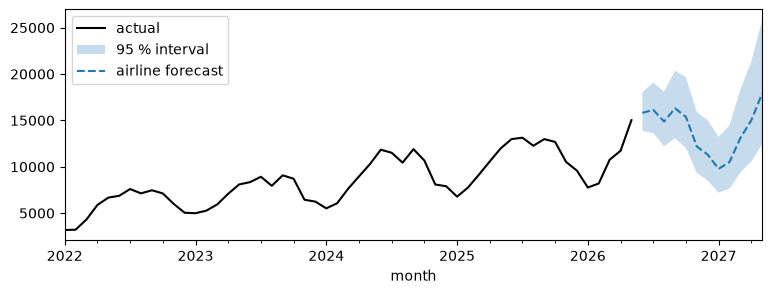

In [34]:
future = pd.date_range("2026-06-01", periods=12, freq="MS")
outlook = airline_forecast(y, future)
ax = y["2022":].plot(figsize=(9, 3), color="black", label="actual")
ax.fill_between(outlook.index, outlook["lower"], outlook["upper"], alpha=0.25, label="95 % interval")
outlook["mean"].plot(ax=ax, ls="--", label="airline forecast")
ax.legend(loc="upper left")
print(f"expected total June 2026 to May 2027: {outlook['mean'].sum():,.0f} (last 12 months: {y['2025-06':].sum():,})")
outlook.round(0).iloc[[0, 1, 6, 11]]

The model expects about a fifth more reviews over the next twelve months than in the last twelve, which continues the growth of recent years. Three caveats belong in the report, next to the numbers:

1. Reviews are a proxy for stays, and the series overstates growth because listings that left the platform are missing from the snapshot (block 1).
2. May 2026 was unusually high; the airline model reacts strongly to the last months, so a single high month raises the whole forecast.
3. The EU rules on short-term rental data (Regulation (EU) 2024/1028) apply from 20 May 2026; if enforcement removes listings, the coming months will fall below the interval, and the model should be refitted or the change modelled as a new break.

The intervals are for single months. The interval for the twelve-month total is not the sum of the monthly limits (errors partly cancel); it would need a simulation from the model, as in block 1.

> **Note.** Tuning on the backtest makes it optimistic. The choices of this session (start ETS in 2022, mark March 2020 to December 2021 as missing) were made after looking at the series, so the backtest numbers are somewhat optimistic. For an honest estimate of future accuracy, hold out a final period that no choice has seen.

```mermaid
flowchart TD
    B["Backtest results<br/>(MASE per fold)"] --> Q1{"Clearly better than<br/>the best baseline?"}
    Q1 -->|no| Q2{"Gives intervals or<br/>other needed outputs?"}
    Q1 -->|yes| Q3{"Stable across folds,<br/>no very bad year?"}
    Q2 -->|yes| R1["Use it with the baseline<br/>as a benchmark"]
    Q2 -->|no| R2["Use the baseline"]
    Q3 -->|yes| R3["Use the model"]
    Q3 -->|no| R1
```

## Check your understanding

1. For a forecast made at the end of May 2026 for March 2027, which of these features may be used: lag 1, lag 6, lag 12, the month, a 3-month rolling mean of `y.shift(12)`?
2. Why can a gradient-boosting model trained on months with at most 12,000 reviews not forecast 15,000? How does the growth target change this?
3. Why does the MASE scale in this notebook use only the training months since 2022?
4. A colleague reports that the forecast improves a lot when the observed temperature of the test months is added. Why is that comparison not fair?
5. ETS beat seasonal naive × growth on the hold-out year but not in the first fold. Which evidence do you trust more, and why?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper* and *Predict* tasks in the markdown cell below the task before running any code, *Code* and *Pairs* tasks in the empty code cells. Stretch tasks are for pairs who finish early. The core cells above (`y`, `train`, `test`, `covid`, `table`, `mae`, `mase`, `folds`) must have been run.

### 2.1 · Earlier forecast origins

*Predict · 5 min*

> The backtest starts at March 2024, when ETS (fitted since January 2022) has 26 months of training data. A colleague wants more folds and adds origins every three months from June 2023. Predict: will ETS's mean MASE over the folds go up or down, and why? What would you expect for the airline model?

*Source:* original exercise for this course; background: [*Forecasting: Principles and Practice*, time series cross-validation](https://otexts.com/fpp3/toolbox.html#sec-tscv)

*Your answer:*

### 2.2 · MASE of 1.2

*Paper · 3 min*

> A forecast has a MASE of 1.2. What does it mean?

*Source:* [Hyndman & Koehler (2006), "Another look at measures of forecast accuracy", *International Journal of Forecasting*](https://doi.org/10.1016/j.ijforecast.2006.03.001)

*Your answer:*

### 2.3 · MASE by hand

*Paper · 5 min*

> A quarterly series (season length m = 4) has the training values 10, 14, 8, 12, 11, 15, 9, 13. The next two quarters are 12 and 16; a model forecast 13 and 14. Compute the MAE of the model, the scale of MASE (the mean absolute error of the seasonal naive forecast on the training data) and the MASE. Is the model better than the seasonal naive rule?

*Source:* original exercise for this course; background: [Hyndman & Koehler (2006)](https://doi.org/10.1016/j.ijforecast.2006.03.001)

*Your answer:*

### 2.4 · Bookable nights are not demand

*Code · 15 min*

> Load the calendar of the snapshot (`pd.read_parquet("case-study/data/airbnb/calendar.parquet")`: one row per listing and night, with `available` True or False) and compute the share of nights still available per month for the next twelve months. Plot it. Why is this not a forecast of demand? Name two reasons why a night can be unavailable.

*Source:* original exercise for this course; background: [Inside Airbnb: Data assumptions](https://insideairbnb.com/data-assumptions/)

### 2.5 · Backtest origins every month

*Pairs · 20 min*

> The notebook backtests from six origins, three months apart (March 2024 to June 2025), each with a 12-month horizon. Repeat the backtest for the seasonal naive forecast and the seasonal naive forecast times growth with origins every month over the same period (16 origins). Report the mean and the worst MAE per model. Do the rankings change? Why are neighbouring folds now strongly correlated, and what does that mean for the number of "independent" tests?

*Source:* original exercise for this course; background: [*Forecasting: Principles and Practice*, time series cross-validation](https://otexts.com/fpp3/toolbox.html#sec-tscv)

### 2.6 · Level or growth as the target?

*Code · 20 min*

> *Stretch:* The lag model of the notebook predicts the yearly growth `log y - log y.shift(12)` from `lag12`, `lag24` and the month, and drops the rows touched by the pandemic. Build the same table, but with the level `log y` as the target. Fit `HistGradientBoostingRegressor(min_samples_leaf=5, random_state=0)` on the rows up to May 2025 and forecast the hold-out year with both targets. Compare the MAE and plot both forecasts against `test`. Which target can forecast values above anything seen in training, and why?

*Source:* original exercise for this course; background: [scikit-learn example: Lagged features for time series forecasting](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html)

## Debrief (15 min)

- **Earlier origins (2.1).** Collect the predictions before revealing the reasoning: a shorter history after the break hurts the model that cuts the history (ETS) much more than the one that skips the break (airline).
- **MASE (2.2, 2.3).** Compare the scales on the board. The common mistake is to compute the scale on the test data, or with m = 1 instead of the season length.
- **Calendar (2.4).** Ask why near months look busier than far months: the share of booked or blocked nights grows as the date approaches. Availability is not demand.
- **Backtest origins (2.5).** Ask how many of the sixteen folds are really independent when neighbouring test years share eleven months.
- **Bridge to the next session.** Forecasting closes the Airbnb part of the course: the same discipline (a baseline, an honest split in time, a metric chosen in advance, an interval with its caveats) carries over to the text models of Sessions 13–16.

## Further reading

- Hyndman, R. J., Athanasopoulos, G., Garza, A., Challu, C., Mergenthaler, M. and Olivares, K. G. (2026). *Forecasting: Principles and Practice, the Pythonic Way*. OTexts. Chapter 5 (the forecaster's toolbox: accuracy, time series cross-validation) and Chapter 7 (regression with predictors). https://otexts.com/fpppy/
- Hyndman, R. J. and Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001
- Makridakis, S., Spiliotis, E. and Assimakopoulos, V. (2022). M5 accuracy competition: results, findings, and conclusions. *International Journal of Forecasting*, 38(4), 1346–1364. https://doi.org/10.1016/j.ijforecast.2021.11.013
- scikit-learn developers. *Lagged features for time series forecasting* and *Time-related feature engineering* (gallery examples). https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html
- Fanaee-T, H. and Gama, J. (2014). Event labeling combining ensemble detectors and background knowledge. *Progress in Artificial Intelligence*, 2, 113–127 (the Bike Sharing Demand data, OpenML dataset 44063).
- Open-Meteo. *Historical weather API*. https://open-meteo.com/en/docs/historical-weather-api
- Regulation (EU) 2024/1028 on data collection and sharing relating to short-term accommodation rental services. https://eur-lex.europa.eu/eli/reg/2024/1028/oj
- Extras of this block, with provenance in [extras/README.md](extras/README.md): [08 lagged features](extras/08-lagged-features-gradient-boosting.ipynb), [09 time-related features](extras/09-time-related-feature-engineering.ipynb), [10 MLForecast walkthrough](extras/10-mlforecast-walkthrough.ipynb), [11 backtesting](extras/11-backtesting.ipynb), [12 StatsForecast cross-validation](extras/12-statsforecast-cross-validation.ipynb), [13 forecasting metrics](extras/13-forecasting-metrics.ipynb).